In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import confusion_matrix, accuracy_score, classification_report

In [2]:
df = pd.read_csv("Hotel Reservations.csv")

print("First 5 rows:")
print(df.head())
print("\nLast 5 rows:")
print(df.tail())
print("\nShape:", df.shape)
print("\nColumns:")
print(df.columns)
print("\nInfo:")
print(df.info())
print("\nDescriptive statistics:")
print(df.describe())

First 5 rows:
  Booking_ID  no_of_adults  no_of_children  no_of_weekend_nights  \
0   INN00001             2               0                     1   
1   INN00002             2               0                     2   
2   INN00003             1               0                     2   
3   INN00004             2               0                     0   
4   INN00005             2               0                     1   

   no_of_week_nights type_of_meal_plan  required_car_parking_space  \
0                  2       Meal Plan 1                           0   
1                  3      Not Selected                           0   
2                  1       Meal Plan 1                           0   
3                  2       Meal Plan 1                           0   
4                  1      Not Selected                           0   

  room_type_reserved  lead_time  arrival_year  arrival_month  arrival_date  \
0        Room_Type 1        224          2017             10             2   


In [3]:
print("\nMissing values per column:")
print(df.isnull().sum())
print("\nDuplicate rows:", df.duplicated().sum())
print("Unique Booking IDs:", df['Booking_ID'].nunique())


Missing values per column:
Booking_ID                              0
no_of_adults                            0
no_of_children                          0
no_of_weekend_nights                    0
no_of_week_nights                       0
type_of_meal_plan                       0
required_car_parking_space              0
room_type_reserved                      0
lead_time                               0
arrival_year                            0
arrival_month                           0
arrival_date                            0
market_segment_type                     0
repeated_guest                          0
no_of_previous_cancellations            0
no_of_previous_bookings_not_canceled    0
avg_price_per_room                      0
no_of_special_requests                  0
booking_status                          0
dtype: int64

Duplicate rows: 0
Unique Booking IDs: 36275


In [4]:
print("\nBooking status counts:")
print(df['booking_status'].value_counts())
print("\nBooking status percentage:")
print(df['booking_status'].value_counts(normalize=True) * 100)


Booking status counts:
booking_status
Not_Canceled    24390
Canceled        11885
Name: count, dtype: int64

Booking status percentage:
booking_status
Not_Canceled    67.236389
Canceled        32.763611
Name: proportion, dtype: float64


In [5]:
dates = pd.to_datetime(dict(year=df['arrival_year'],
                            month=df['arrival_month'],
                            day=df['arrival_date']), errors='coerce')
print("\nInvalid arrival dates:", dates.isna().sum())
print(df[dates.isna()][['arrival_year', 'arrival_month', 'arrival_date']].drop_duplicates())

# 3b. Zero average room price
zero_price = df[df['avg_price_per_room'] == 0]
print("\nRows with zero room price:", len(zero_price))
print(zero_price['market_segment_type'].value_counts())
print(zero_price['booking_status'].value_counts())

# 3c. Zero adults
zero_adults = df[df['no_of_adults'] == 0]
print("\nRows with zero adults:", len(zero_adults))
print(zero_adults['no_of_children'].describe())

# 3d. Bookings with zero nights
print("\nRows with zero total nights:",
      ((df['no_of_weekend_nights'] + df['no_of_week_nights']) == 0).sum())



Invalid arrival dates: 37
      arrival_year  arrival_month  arrival_date
2626          2018              2            29

Rows with zero room price: 545
market_segment_type
Complementary    354
Online           191
Name: count, dtype: int64
booking_status
Not_Canceled    539
Canceled          6
Name: count, dtype: int64

Rows with zero adults: 139
count    139.000000
mean       2.028777
std        0.206505
min        1.000000
25%        2.000000
50%        2.000000
75%        2.000000
max        3.000000
Name: no_of_children, dtype: float64

Rows with zero total nights: 78


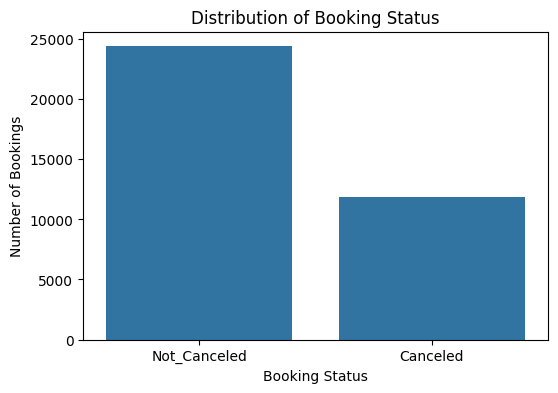

In [25]:
# Numeric copy of the target for calculating cancellation rates (1 = Canceled)
df['cancelled'] = df['booking_status'].map({'Not_Canceled': 0, 'Canceled': 1})
# ---- 4.1 Cancellation distribution
plt.figure(figsize=(6, 4))
sns.countplot(x='booking_status', data=df)
plt.title("Distribution of Booking Status")
plt.xlabel("Booking Status")
plt.ylabel("Number of Bookings")
plt.show()

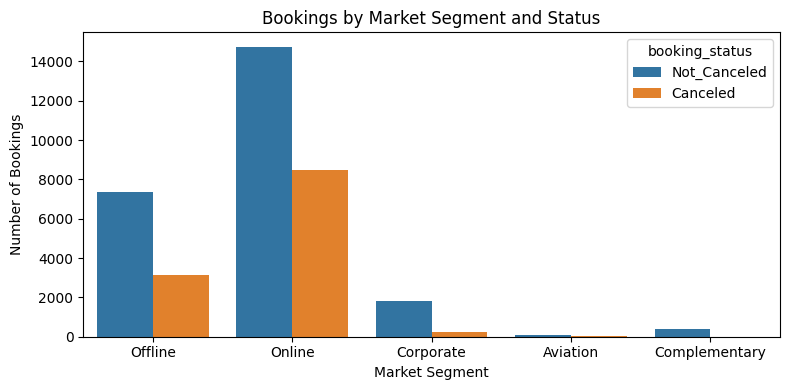


Cancellation rate (%) by market segment:
  market_segment_type  cancellation_rate
0            Aviation          29.600000
1       Complementary           0.000000
2           Corporate          10.907288
3             Offline          29.948708
4              Online          36.508142


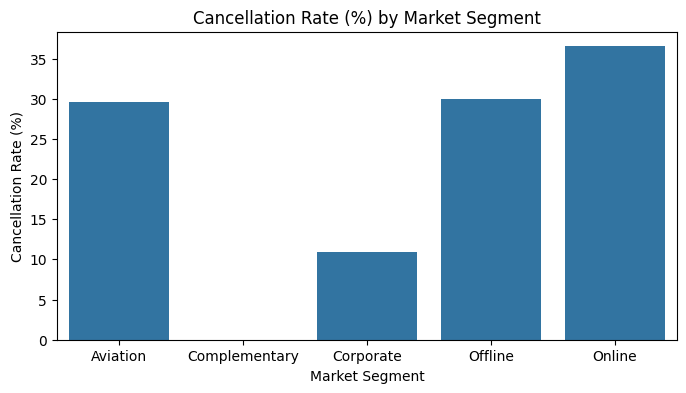

In [26]:
# ---- 4.2 Market segment (our customer-group analysis)
plt.figure(figsize=(8, 4))
sns.countplot(x='market_segment_type', hue='booking_status', data=df)
plt.title("Bookings by Market Segment and Status")
plt.xlabel("Market Segment")
plt.ylabel("Number of Bookings")
plt.tight_layout()
plt.show()

segment_rate = df.groupby('market_segment_type')['cancelled'].mean() * 100
segment_rate = segment_rate.reset_index()
segment_rate.columns = ['market_segment_type', 'cancellation_rate']
print("\nCancellation rate (%) by market segment:")
print(segment_rate)

plt.figure(figsize=(8, 4))
sns.barplot(x='market_segment_type', y='cancellation_rate', data=segment_rate)
plt.title("Cancellation Rate (%) by Market Segment")
plt.xlabel("Market Segment")
plt.ylabel("Cancellation Rate (%)")
plt.show()


Cancellation rate (%) by repeated guest (0 = new, 1 = repeated):
   repeated_guest  cancellation_rate
0               0          33.580422
1               1           1.720430


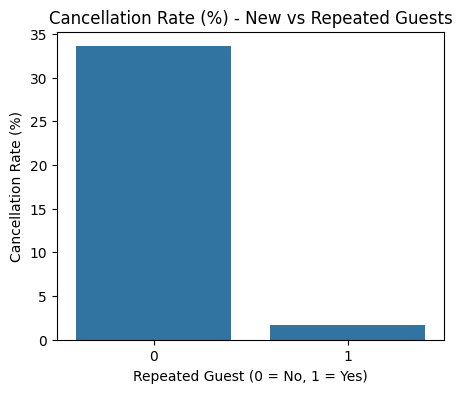

In [27]:
# ---- 4.3 Repeated guest vs new guest
repeat_rate = df.groupby('repeated_guest')['cancelled'].mean() * 100
repeat_rate = repeat_rate.reset_index()
repeat_rate.columns = ['repeated_guest', 'cancellation_rate']
print("\nCancellation rate (%) by repeated guest (0 = new, 1 = repeated):")
print(repeat_rate)

plt.figure(figsize=(5, 4))
sns.barplot(x='repeated_guest', y='cancellation_rate', data=repeat_rate)
plt.title("Cancellation Rate (%) - New vs Repeated Guests")
plt.xlabel("Repeated Guest (0 = No, 1 = Yes)")
plt.ylabel("Cancellation Rate (%)")
plt.show()


Average lead time by booking status:
                  count        mean        std  min   25%    50%    75%    max
booking_status                                                                
Canceled        11885.0  139.215482  98.947731  0.0  55.0  122.0  205.0  443.0
Not_Canceled    24390.0   58.927224  64.028714  0.0  10.0   39.0   86.0  386.0


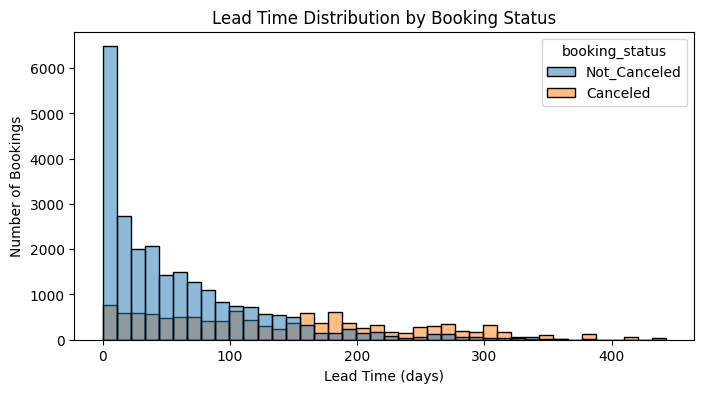

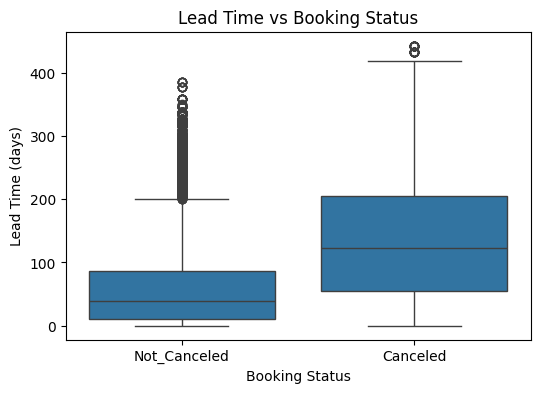

In [28]:

# ---- 4.4 Lead time
print("\nAverage lead time by booking status:")
print(df.groupby('booking_status')['lead_time'].describe())

plt.figure(figsize=(8, 4))
sns.histplot(data=df, x='lead_time', hue='booking_status', bins=40)
plt.title("Lead Time Distribution by Booking Status")
plt.xlabel("Lead Time (days)")
plt.ylabel("Number of Bookings")
plt.show()

plt.figure(figsize=(6, 4))
sns.boxplot(x='booking_status', y='lead_time', data=df)
plt.title("Lead Time vs Booking Status")
plt.xlabel("Booking Status")
plt.ylabel("Lead Time (days)")
plt.show()


Cancellation rate (%) by room type:
  room_type_reserved  cancellation_rate
0        Room_Type 1          32.250267
1        Room_Type 2          32.947977
2        Room_Type 3          28.571429
3        Room_Type 4          34.158825
4        Room_Type 5          27.169811
5        Room_Type 6          42.028986
6        Room_Type 7          22.784810

Cancellation rate (%) by meal plan:
  type_of_meal_plan  cancellation_rate
0       Meal Plan 1          31.180169
1       Meal Plan 2          45.567322
2       Meal Plan 3          20.000000
3      Not Selected          33.118908


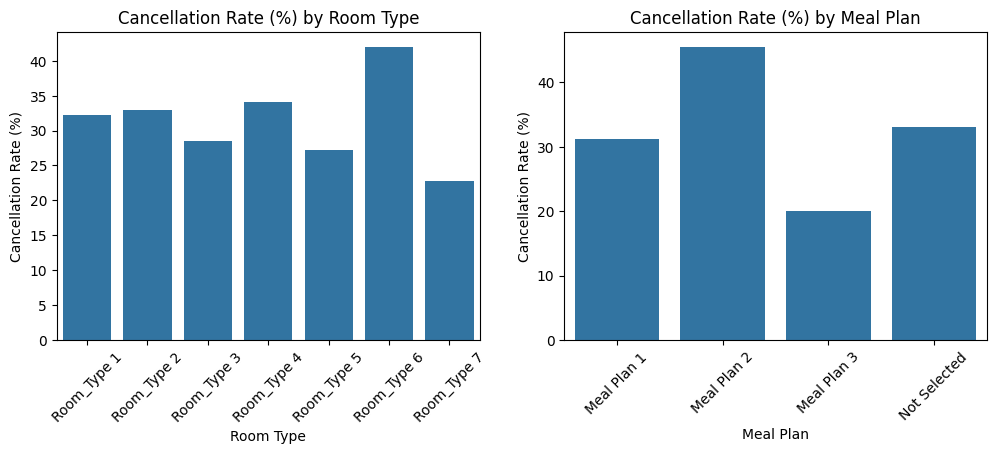

In [29]:
# ---- 4.5 Room type and meal plan
room_rate = df.groupby('room_type_reserved')['cancelled'].mean() * 100
room_rate = room_rate.reset_index()
room_rate.columns = ['room_type_reserved', 'cancellation_rate']
meal_rate = df.groupby('type_of_meal_plan')['cancelled'].mean() * 100
meal_rate = meal_rate.reset_index()
meal_rate.columns = ['type_of_meal_plan', 'cancellation_rate']
print("\nCancellation rate (%) by room type:")
print(room_rate)
print("\nCancellation rate (%) by meal plan:")
print(meal_rate)

plt.figure(figsize=(12, 4))
plt.subplot(1, 2, 1)
sns.barplot(x='room_type_reserved', y='cancellation_rate', data=room_rate)
plt.title("Cancellation Rate (%) by Room Type")
plt.xlabel("Room Type")
plt.ylabel("Cancellation Rate (%)")
plt.xticks(rotation=45)
plt.subplot(1, 2, 2)
sns.barplot(x='type_of_meal_plan', y='cancellation_rate', data=meal_rate)
plt.title("Cancellation Rate (%) by Meal Plan")
plt.xlabel("Meal Plan")
plt.ylabel("Cancellation Rate (%)")
plt.xticks(rotation=45)
plt.show()


Average room price by booking status:
                  count        mean        std  min    25%    50%     75%  \
booking_status                                                              
Canceled        11885.0  110.589966  32.264394  0.0  89.27  108.0  126.36   
Not_Canceled    24390.0   99.931412  35.872154  0.0  77.86   95.0  119.10   

                  max  
booking_status         
Canceled        540.0  
Not_Canceled    375.5  


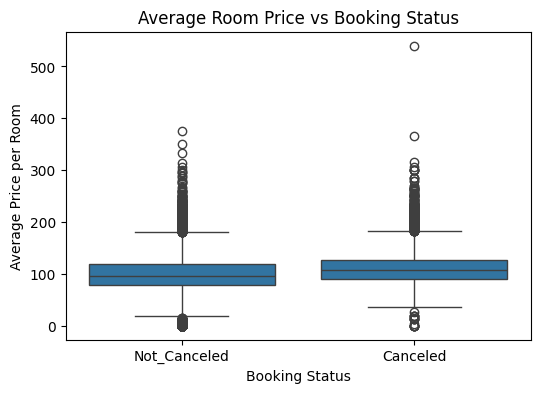

In [30]:
# ---- 4.6 Price
print("\nAverage room price by booking status:")
print(df.groupby('booking_status')['avg_price_per_room'].describe())

plt.figure(figsize=(6, 4))
sns.boxplot(x='booking_status', y='avg_price_per_room', data=df)
plt.title("Average Room Price vs Booking Status")
plt.xlabel("Booking Status")
plt.ylabel("Average Price per Room")
plt.show()


Cancellation rate (%) by number of special requests:
   no_of_special_requests  cancellation_rate
0                       0          43.206755
1                       1          23.766816
2                       2          14.596700
3                       3           0.000000
4                       4           0.000000
5                       5           0.000000


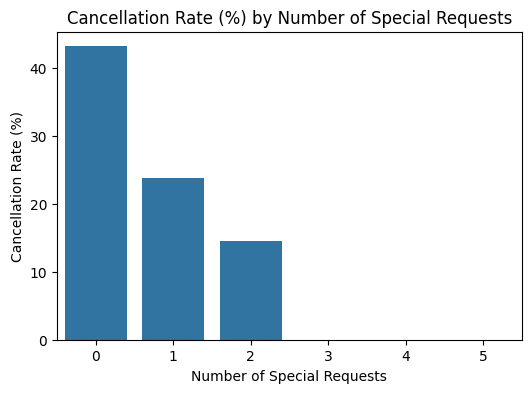

In [31]:
# ---- 4.7 Special requests
request_rate = df.groupby('no_of_special_requests')['cancelled'].mean() * 100
request_rate = request_rate.reset_index()
request_rate.columns = ['no_of_special_requests', 'cancellation_rate']
print("\nCancellation rate (%) by number of special requests:")
print(request_rate)

plt.figure(figsize=(6, 4))
sns.barplot(x='no_of_special_requests', y='cancellation_rate', data=request_rate)
plt.title("Cancellation Rate (%) by Number of Special Requests")
plt.xlabel("Number of Special Requests")
plt.ylabel("Cancellation Rate (%)")
plt.show()



Cancellation rate (%) by arrival month:
    arrival_month  cancellation_rate
0               1           2.366864
1               2          25.234742
2               3          29.686175
3               4          36.366959
4               5          36.489607
5               6          40.305963
6               7          45.000000
7               8          39.024390
8               9          33.355021
9              10          35.358285
10             11          29.362416
11             12          13.306852

Cancellation rate (%) by arrival year:
   arrival_year  cancellation_rate
0          2017          14.752840
1          2018          36.705756


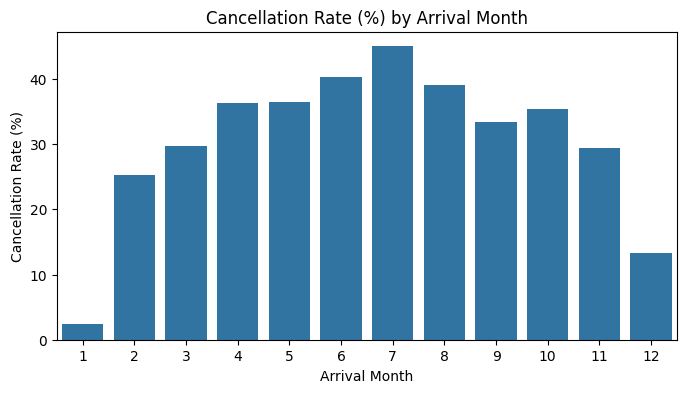

In [32]:
# ---- 4.8 Arrival month and arrival year
month_rate = df.groupby('arrival_month')['cancelled'].mean() * 100
month_rate = month_rate.reset_index()
month_rate.columns = ['arrival_month', 'cancellation_rate']
year_rate = df.groupby('arrival_year')['cancelled'].mean() * 100
year_rate = year_rate.reset_index()
year_rate.columns = ['arrival_year', 'cancellation_rate']
print("\nCancellation rate (%) by arrival month:")
print(month_rate)
print("\nCancellation rate (%) by arrival year:")
print(year_rate)

plt.figure(figsize=(8, 4))
sns.barplot(x='arrival_month', y='cancellation_rate', data=month_rate)
plt.title("Cancellation Rate (%) by Arrival Month")
plt.xlabel("Arrival Month")
plt.ylabel("Cancellation Rate (%)")
plt.show()

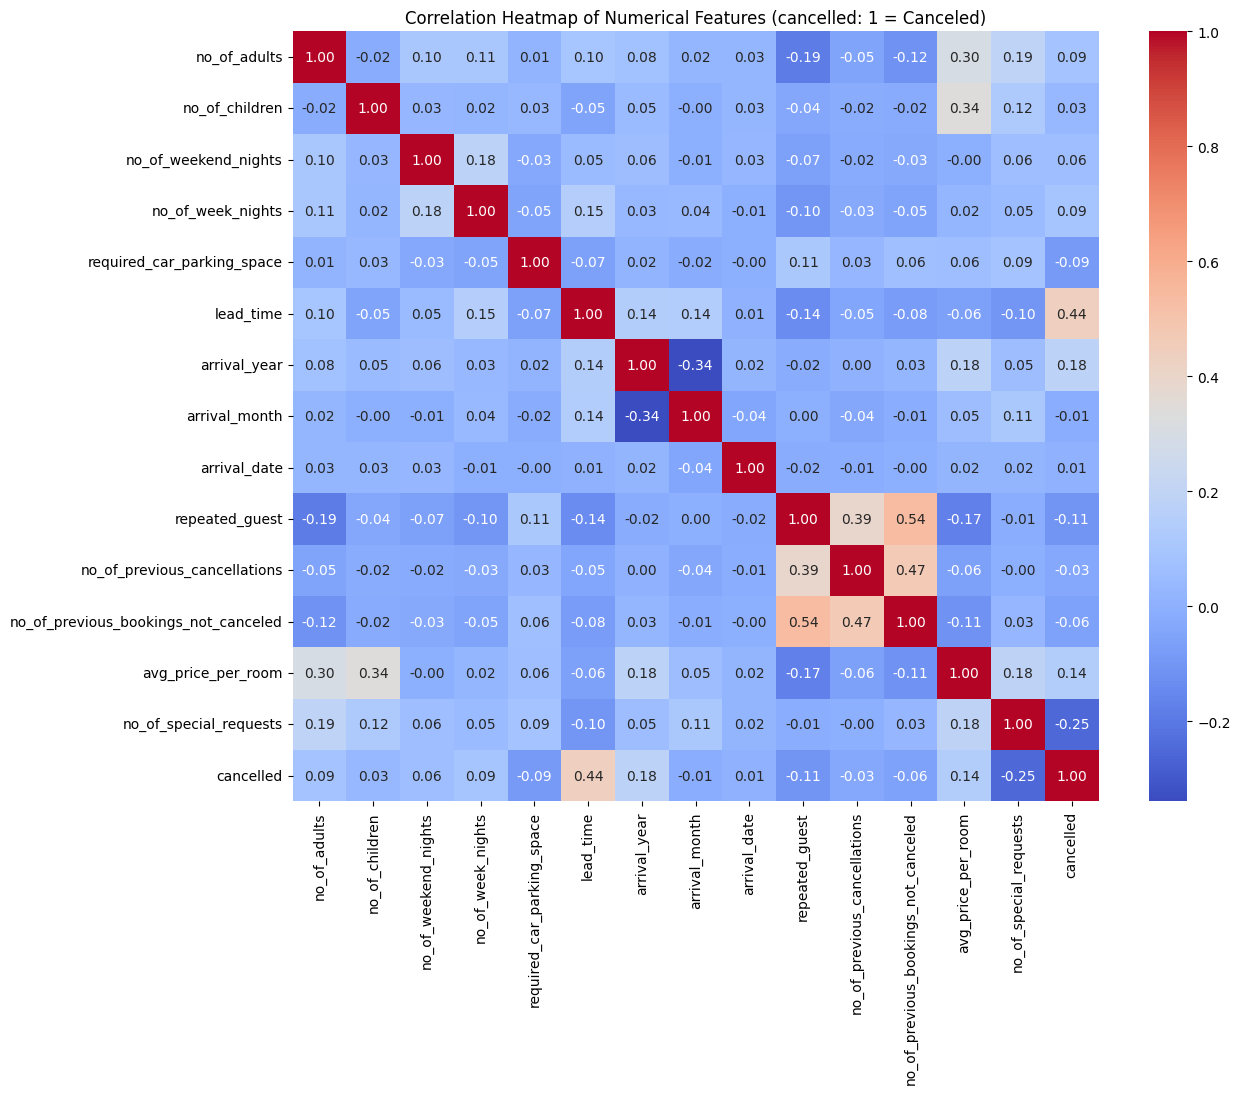


Correlation of every numerical feature with 'cancelled':
cancelled                               1.000000
lead_time                               0.438538
arrival_year                            0.179529
avg_price_per_room                      0.142569
no_of_week_nights                       0.092996
no_of_adults                            0.086920
no_of_weekend_nights                    0.061563
no_of_children                          0.033078
arrival_date                            0.010629
arrival_month                          -0.011233
no_of_previous_cancellations           -0.033728
no_of_previous_bookings_not_canceled   -0.060179
required_car_parking_space             -0.086185
repeated_guest                         -0.107287
no_of_special_requests                 -0.253070
Name: cancelled, dtype: float64


In [33]:
# ---- 4.9 Correlation heatmap (numerical columns only, before encoding)
corr = df.corr(numeric_only=True)
plt.figure(figsize=(13, 10))
sns.heatmap(corr, annot=True, fmt='.2f', cmap='coolwarm')
plt.title("Correlation Heatmap of Numerical Features (cancelled: 1 = Canceled)")
plt.show()

print("\nCorrelation of every numerical feature with 'cancelled':")
print(corr['cancelled'].sort_values(ascending=False))

In [15]:
# =====================================================
# 5. PREPROCESSING
# =====================================================
df_model = df.copy()

# Drop: ID (identifier), booking_status (the target in text form - leakage if kept),
# arrival_year (only two years of data) and arrival_date (day of month, weak, holds the invalid dates)
df_model.drop(columns=['Booking_ID', 'booking_status', 'arrival_year', 'arrival_date'],
              inplace=True)

# Encode the text columns with LabelEncoder
cat_cols = ['type_of_meal_plan', 'room_type_reserved', 'market_segment_type']
label_enc = LabelEncoder()
for col in cat_cols:
    df_model[col] = label_enc.fit_transform(df_model[col])
    print("\nEncoding for", col, ":")
    print(dict(zip(label_enc.classes_, label_enc.transform(label_enc.classes_))))

print("\nColumns used in the model:")
print(df_model.columns)
print(df_model.info())


Encoding for type_of_meal_plan :
{'Meal Plan 1': np.int64(0), 'Meal Plan 2': np.int64(1), 'Meal Plan 3': np.int64(2), 'Not Selected': np.int64(3)}

Encoding for room_type_reserved :
{'Room_Type 1': np.int64(0), 'Room_Type 2': np.int64(1), 'Room_Type 3': np.int64(2), 'Room_Type 4': np.int64(3), 'Room_Type 5': np.int64(4), 'Room_Type 6': np.int64(5), 'Room_Type 7': np.int64(6)}

Encoding for market_segment_type :
{'Aviation': np.int64(0), 'Complementary': np.int64(1), 'Corporate': np.int64(2), 'Offline': np.int64(3), 'Online': np.int64(4)}

Columns used in the model:
Index(['no_of_adults', 'no_of_children', 'no_of_weekend_nights',
       'no_of_week_nights', 'type_of_meal_plan', 'required_car_parking_space',
       'room_type_reserved', 'lead_time', 'arrival_month',
       'market_segment_type', 'repeated_guest', 'no_of_previous_cancellations',
       'no_of_previous_bookings_not_canceled', 'avg_price_per_room',
       'no_of_special_requests', 'cancelled'],
      dtype='str')
<class 'p

In [16]:
# =====================================================
# 6. SELECT X AND y, TRAIN-TEST SPLIT, SCALING
# =====================================================

X = df_model.drop(['cancelled', 'no_of_special_requests'], axis=1)
y = df_model['cancelled']

print("\nFeatures used:", list(X.columns))

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y)

print("Training set:", X_train.shape, " Test set:", X_test.shape)
print("Cancelled share in train:", round(y_train.mean() * 100, 2), "%")
print("Cancelled share in test :", round(y_test.mean() * 100, 2), "%")

# Scaling: fit on training data only
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)


Features used: ['no_of_adults', 'no_of_children', 'no_of_weekend_nights', 'no_of_week_nights', 'type_of_meal_plan', 'required_car_parking_space', 'room_type_reserved', 'lead_time', 'arrival_month', 'market_segment_type', 'repeated_guest', 'no_of_previous_cancellations', 'no_of_previous_bookings_not_canceled', 'avg_price_per_room']
Training set: (29020, 14)  Test set: (7255, 14)
Cancelled share in train: 32.76 %
Cancelled share in test : 32.76 %


In [17]:
# =====================================================
# 7. TRAIN MODELS AND PREDICT
# (scaled data for Logistic Regression, KNN, SVM; original data for the rest)
# =====================================================
# 7.1 Logistic Regression
lr = LogisticRegression(max_iter=1000)
lr.fit(X_train_scaled, y_train)
y_pred_lr = lr.predict(X_test_scaled)

# 7.2 K-Nearest Neighbors
knn = KNeighborsClassifier(n_neighbors=5, metric='euclidean')
knn.fit(X_train_scaled, y_train)
y_pred_knn = knn.predict(X_test_scaled)

# 7.3 Gaussian Naive Bayes
nb = GaussianNB()
nb.fit(X_train, y_train)
y_pred_nb = nb.predict(X_test)

# 7.4 Support Vector Machine (this one takes a minute or two)
svm = SVC(kernel='rbf', random_state=42)
svm.fit(X_train_scaled, y_train)
y_pred_svm = svm.predict(X_test_scaled)

# 7.5 Decision Tree
dt = DecisionTreeClassifier(criterion='entropy', random_state=42)
dt.fit(X_train, y_train)
y_pred_dt = dt.predict(X_test)

# 7.6 Random Forest
rf = RandomForestClassifier(n_estimators=100, random_state=42)
rf.fit(X_train, y_train)
y_pred_rf = rf.predict(X_test)

In [18]:
# =====================================================
# 8. EVALUATION
# =====================================================

predictions = {
    "Logistic Regression": y_pred_lr,
    "KNN": y_pred_knn,
    "Gaussian Naive Bayes": y_pred_nb,
    "SVM": y_pred_svm,
    "Decision Tree": y_pred_dt,
    "Random Forest": y_pred_rf,
}

results = []
cms = {}

for name in predictions:
    y_pred = predictions[name]
    cm = confusion_matrix(y_test, y_pred)
    cms[name] = cm
    acc = accuracy_score(y_test, y_pred)

    print("\n==============================")
    print(name)
    print("==============================")
    print("Accuracy:", round(acc, 4))
    print("\nConfusion Matrix:")
    print(cm)
    print("\nClassification Report:")
    print(classification_report(
        y_test, y_pred,
        target_names=['Not Canceled', 'Canceled'],
        zero_division=0
    ))

    # Metrics for the Canceled class
    tn, fp, fn, tp = cm.ravel()

    precision = tp / (tp + fp) if (tp + fp) > 0 else 0
    recall = tp / (tp + fn) if (tp + fn) > 0 else 0
    f1 = (2 * precision * recall / (precision + recall)
          if (precision + recall) > 0 else 0)

    results.append([name, acc, precision, recall, f1, tn, fp, fn, tp])

comparison = pd.DataFrame(
    results,
    columns=['Model', 'Accuracy', 'Precision (Canceled)',
             'Recall (Canceled)', 'F1 (Canceled)',
             'TN', 'FP', 'FN', 'TP']
)

print("\n\nMODEL COMPARISON TABLE")
print(comparison.round(4).to_string(index=False))
comparison.round(4).to_csv("model_comparison.csv", index=False)


Logistic Regression
Accuracy: 0.7615

Confusion Matrix:
[[4364  514]
 [1216 1161]]

Classification Report:
              precision    recall  f1-score   support

Not Canceled       0.78      0.89      0.83      4878
    Canceled       0.69      0.49      0.57      2377

    accuracy                           0.76      7255
   macro avg       0.74      0.69      0.70      7255
weighted avg       0.75      0.76      0.75      7255


KNN
Accuracy: 0.8066

Confusion Matrix:
[[4310  568]
 [ 835 1542]]

Classification Report:
              precision    recall  f1-score   support

Not Canceled       0.84      0.88      0.86      4878
    Canceled       0.73      0.65      0.69      2377

    accuracy                           0.81      7255
   macro avg       0.78      0.77      0.77      7255
weighted avg       0.80      0.81      0.80      7255


Gaussian Naive Bayes
Accuracy: 0.3775

Confusion Matrix:
[[ 390 4488]
 [  28 2349]]

Classification Report:
              precision    recall  f1

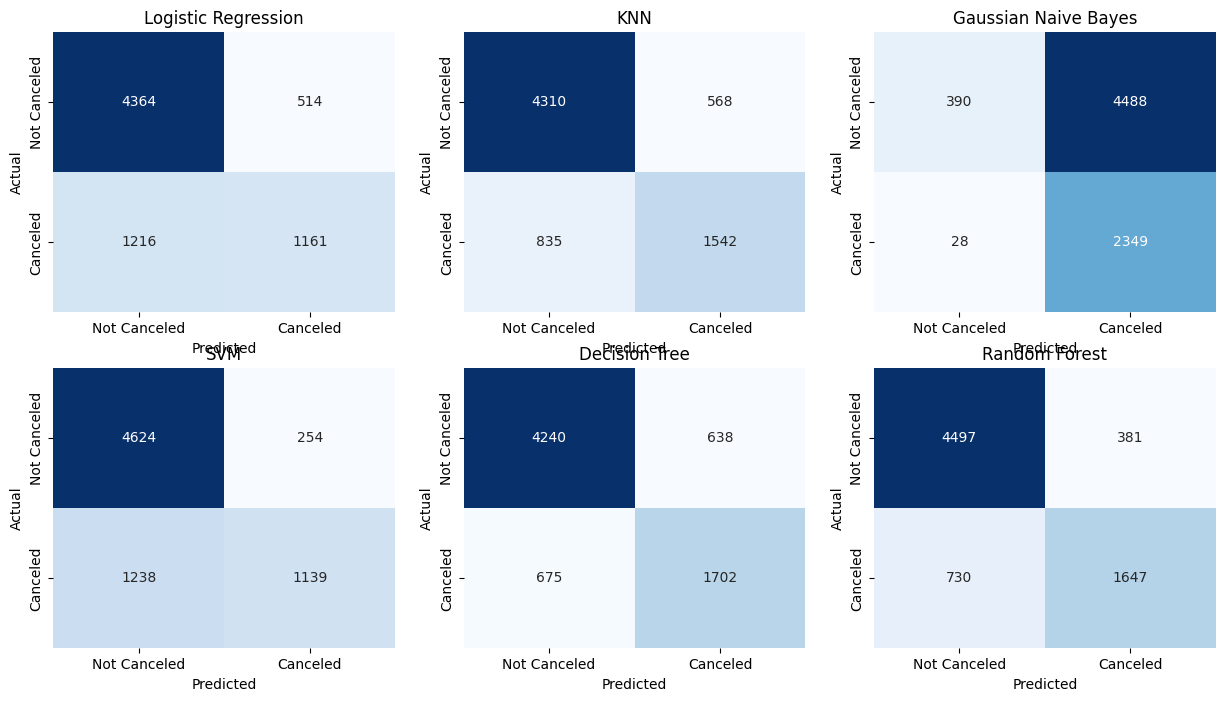

In [34]:
# ---- Confusion matrix heatmaps for all six models
plt.figure(figsize=(15, 8))
i = 1
for name in cms:
    plt.subplot(2, 3, i)
    sns.heatmap(cms[name], annot=True, fmt='d', cmap='Blues', cbar=False,
                xticklabels=['Not Canceled', 'Canceled'],
                yticklabels=['Not Canceled', 'Canceled'])
    plt.title(name)
    plt.xlabel("Predicted")
    plt.ylabel("Actual")
    i = i + 1
plt.show()

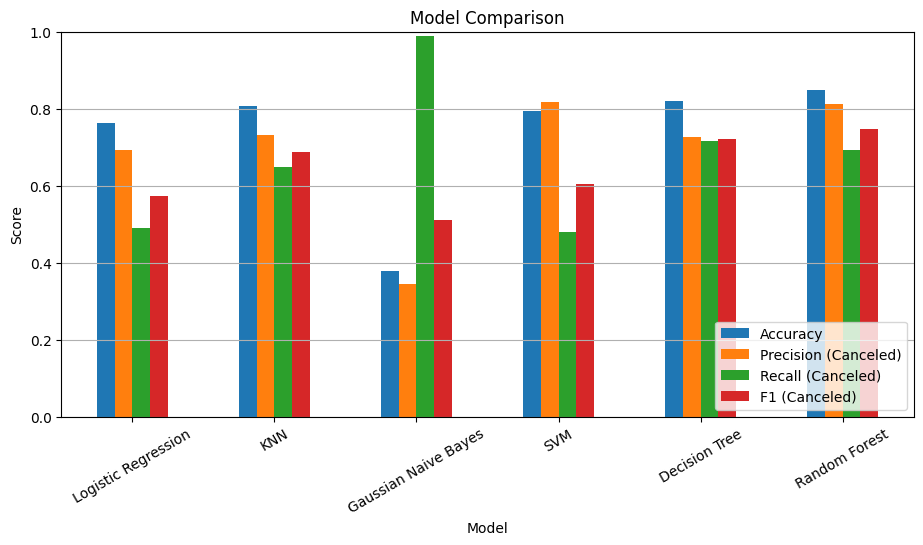

In [35]:
# ---- Bar chart comparing the models
comparison.set_index('Model')[['Accuracy', 'Precision (Canceled)',
                               'Recall (Canceled)', 'F1 (Canceled)']].plot(
    kind='bar', figsize=(11, 5))
plt.title("Model Comparison")
plt.ylabel("Score")
plt.ylim(0, 1)
plt.xticks(rotation=30)
plt.legend(loc='lower right')
plt.grid(True, axis='y')
plt.show()

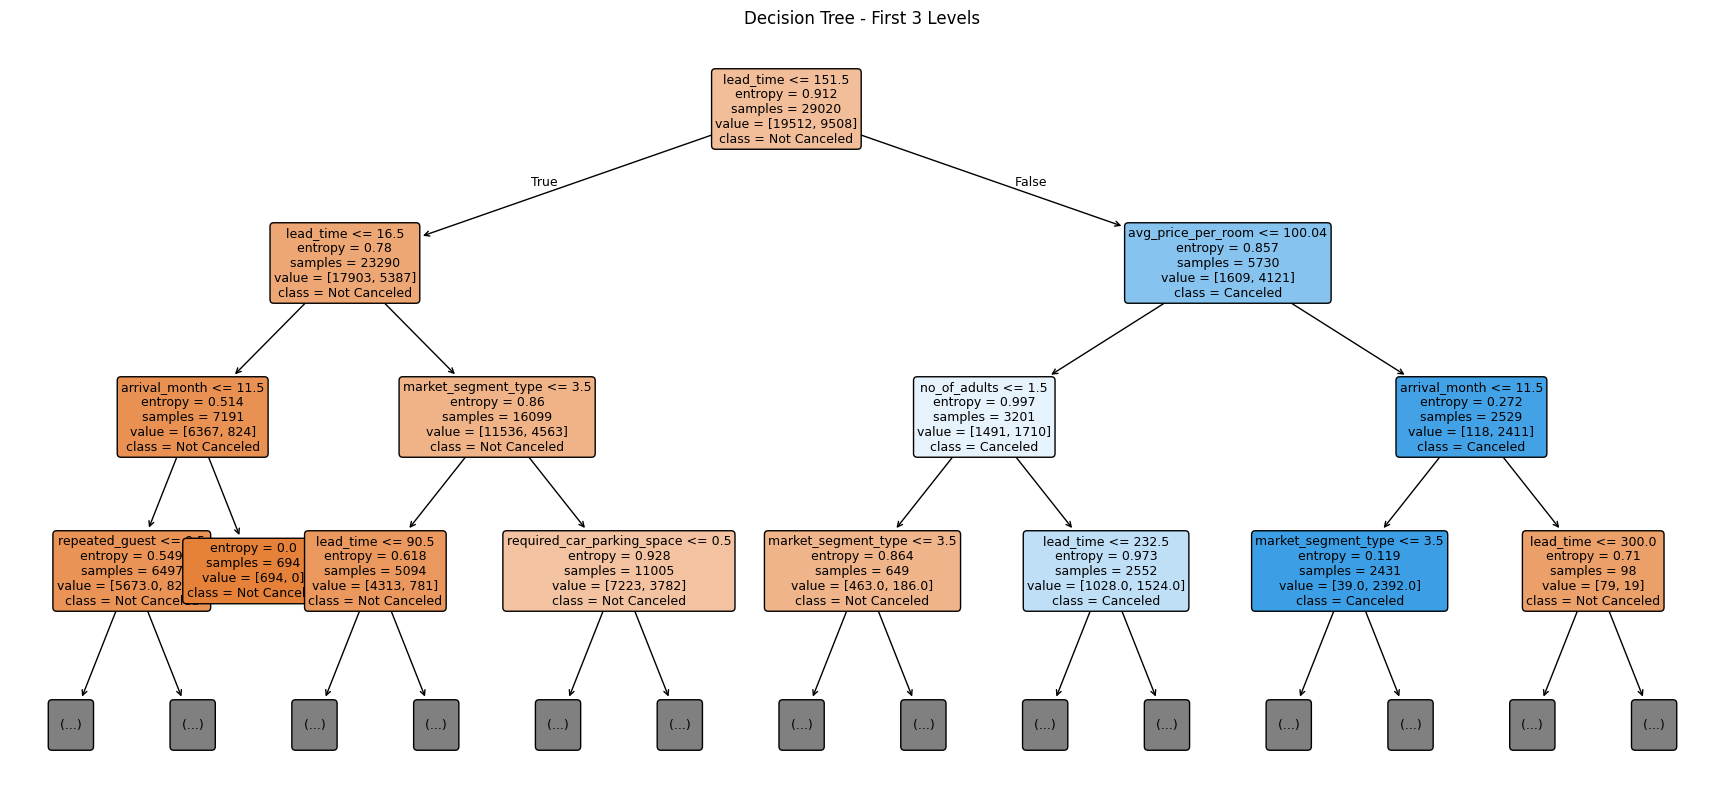


Decision Tree depth: 56  leaves: 5010


In [36]:
# =====================================================
# 9. INTERPRETATION OF TREE-BASED MODELS
# =====================================================
# 9.1 First levels of the Decision Tree (real, unscaled values)
plt.figure(figsize=(22, 10))
plot_tree(dt,
          feature_names=X.columns,
          class_names=["Not Canceled", "Canceled"],
          filled=True,
          rounded=True,
          max_depth=3,
          fontsize=9)
plt.title("Decision Tree - First 3 Levels")
plt.show()
print("\nDecision Tree depth:", dt.get_depth(), " leaves:", dt.get_n_leaves())


Random Forest feature importance:
lead_time                               0.4346
avg_price_per_room                      0.2249
arrival_month                           0.1059
no_of_week_nights                       0.0703
no_of_weekend_nights                    0.0460
market_segment_type                     0.0325
no_of_adults                            0.0272
type_of_meal_plan                       0.0183
room_type_reserved                      0.0174
no_of_children                          0.0096
required_car_parking_space              0.0078
repeated_guest                          0.0032
no_of_previous_bookings_not_canceled    0.0021
no_of_previous_cancellations            0.0003
dtype: float64


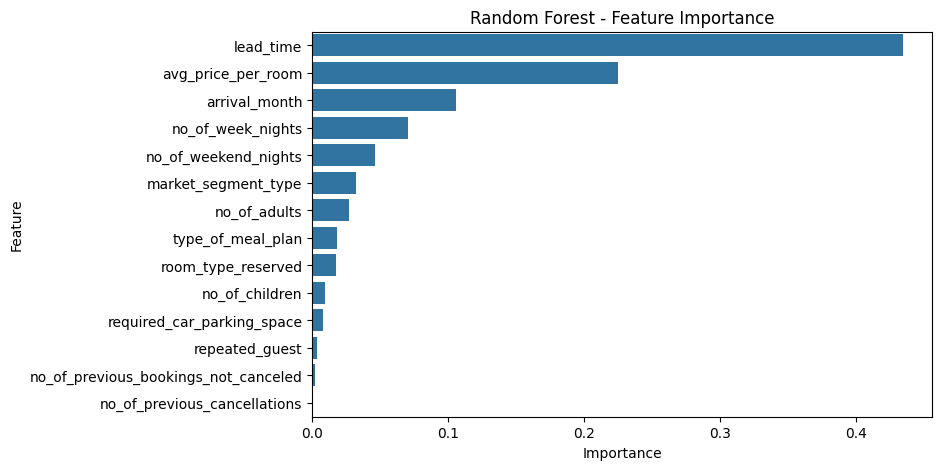

In [37]:
# 9.2 Random Forest feature importance
importance = pd.Series(rf.feature_importances_, index=X.columns).sort_values(ascending=False)
print("\nRandom Forest feature importance:")
print(importance.round(4))

plt.figure(figsize=(8, 5))
sns.barplot(x=importance.values, y=importance.index)
plt.title("Random Forest - Feature Importance")
plt.xlabel("Importance")
plt.ylabel("Feature")
plt.show()

In [24]:
# =====================================================
# 10. SENSITIVITY CHECK: INCLUDE SPECIAL REQUESTS
# =====================================================

X2 = df_model.drop('cancelled', axis=1)

X2_train, X2_test, y2_train, y2_test = train_test_split(
    X2, y, test_size=0.2, random_state=42, stratify=y)

# Random Forest with special requests
rf2 = RandomForestClassifier(n_estimators=100, random_state=42)
rf2.fit(X2_train, y2_train)
y_pred_rf2 = rf2.predict(X2_test)

# Logistic Regression with special requests
sc2 = StandardScaler()
X2_train_scaled = sc2.fit_transform(X2_train)
X2_test_scaled = sc2.transform(X2_test)

lr2 = LogisticRegression(max_iter=1000)
lr2.fit(X2_train_scaled, y2_train)
y_pred_lr2 = lr2.predict(X2_test_scaled)

check = {
    "Random Forest": (y_pred_rf, y_pred_rf2),
    "Logistic Regression": (y_pred_lr, y_pred_lr2)
}

check_rows = []

for name in check:
    for label, pred in zip(
        ["Without special requests", "With special requests"],
        check[name]
    ):
        cm = confusion_matrix(y2_test, pred)
        tn, fp, fn, tp = cm.ravel()

        p = tp / (tp + fp) if (tp + fp) > 0 else 0
        r = tp / (tp + fn) if (tp + fn) > 0 else 0
        f1 = (2 * p * r / (p + r) if (p + r) > 0 else 0)

        check_rows.append([
            name, label, accuracy_score(y_test, pred),
            p, r, f1
        ])

check_df = pd.DataFrame(
    check_rows,
    columns=['Model', 'Feature Set', 'Accuracy',
             'Precision (Canceled)', 'Recall (Canceled)',
             'F1 (Canceled)']
)

print("\nSPECIAL REQUESTS SENSITIVITY CHECK")
print(check_df.round(4).to_string(index=False))


SPECIAL REQUESTS SENSITIVITY CHECK
              Model              Feature Set  Accuracy  Precision (Canceled)  Recall (Canceled)  F1 (Canceled)
      Random Forest Without special requests    0.8469                0.8121             0.6929         0.7478
      Random Forest    With special requests    0.9016                0.8823             0.8073         0.8431
Logistic Regression Without special requests    0.7615                0.6931             0.4884         0.5731
Logistic Regression    With special requests    0.8094                0.7528             0.6226         0.6816
